# 1 - EDA Citra Awal


              EDA DATASET ULTRASOUND
Folder utama       : D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\Mentah
Jumlah gambar      : 2340

----------------------------------------------------------------------
1. INFORMASI DATASET
----------------------------------------------------------------------
Jumlah dataset     : 26
Jumlah gambar      : 2340

Jumlah gambar setiap dataset:
dataset
dataset_1      83
dataset_10     57
dataset_11     77
dataset_12     83
dataset_13     83
dataset_14     83
dataset_15     77
dataset_16     83
dataset_17     83
dataset_18     83
dataset_19     83
dataset_2      49
dataset_20     83
dataset_21     83
dataset_22     83
dataset_23     83
dataset_24     83
dataset_25     74
dataset_26    393
dataset_3      77
dataset_4      10
dataset_5      86
dataset_6     124
dataset_7      77
dataset_8      91
dataset_9      69

----------------------------------------------------------------------
2. STRUKTUR DATA
---------------------------------------------------

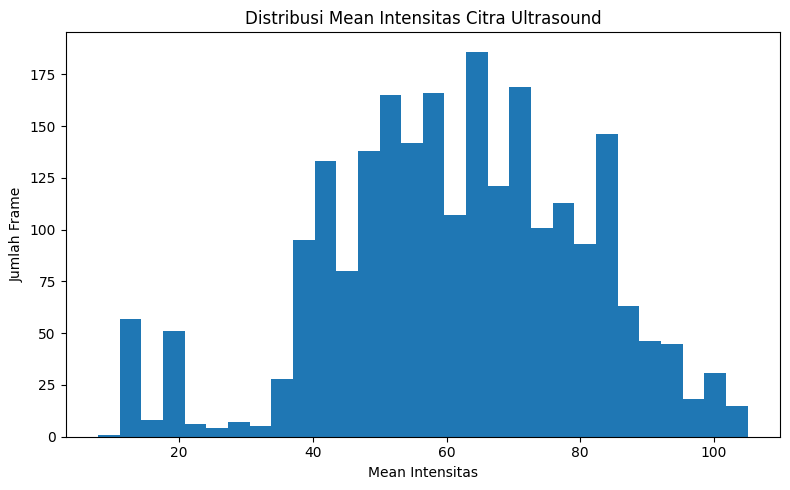

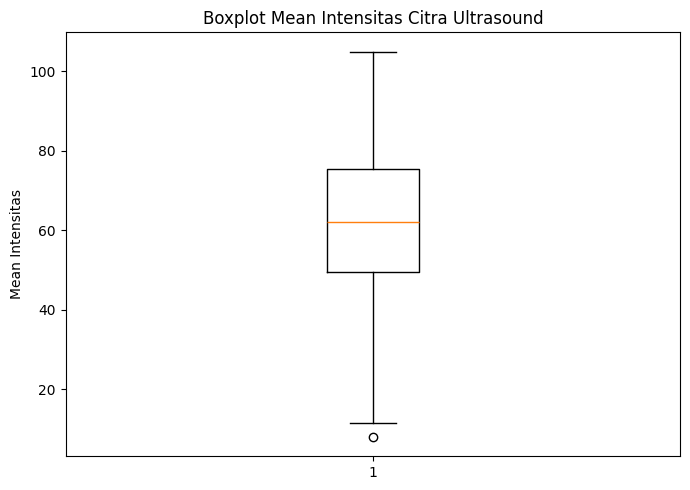

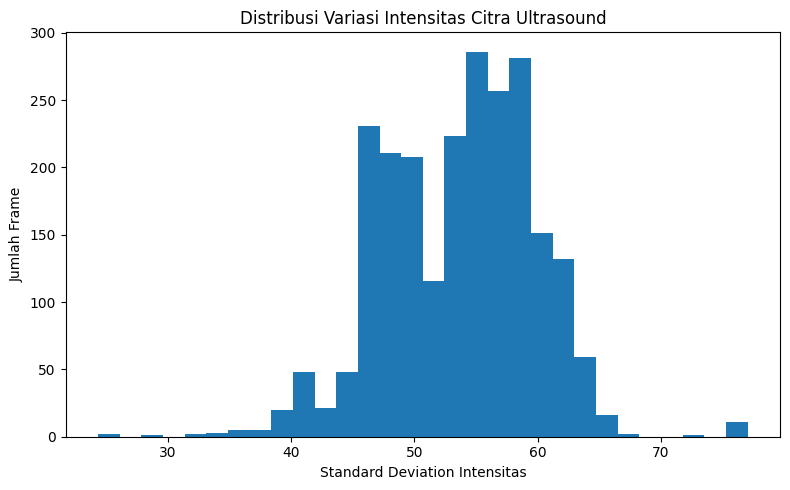


----------------------------------------------------------------------
7. DETEKSI OUTLIER
----------------------------------------------------------------------
Q1                  : 49.37
Q3                  : 75.43
IQR                 : 26.06
Batas bawah         : 10.29
Batas atas          : 114.51
Jumlah outlier      : 1

Daftar kandidat outlier:
  dataset            file  mean  median   std
dataset_5 frame_00004.jpg  7.91     0.0 29.18


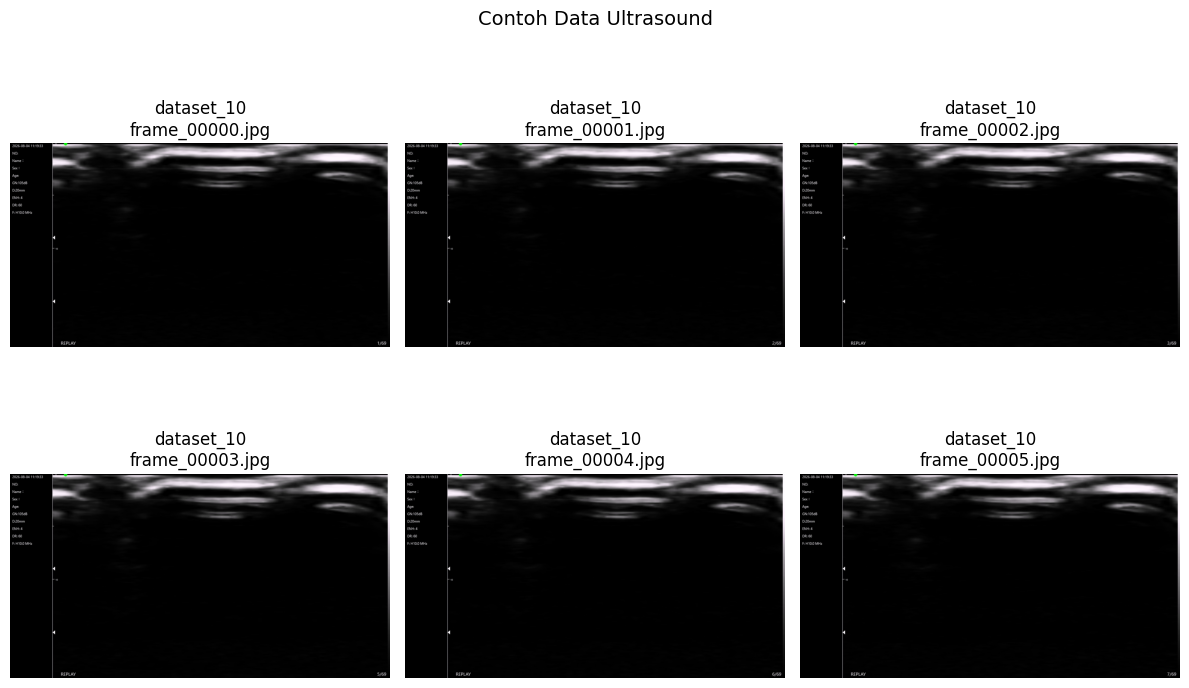


EDA SELESAI
Total dataset : 26
Total gambar  : 2340

Hasil EDA disimpan di:
D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS/Hasil_EDA


In [5]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# KONFIGURASI
# ============================================================

# Folder utama yang berisi 27 folder dataset
DATASET_DIR = r"D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\Mentah"

# Ekstensi gambar yang akan dibaca
EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")


# ============================================================
# 1. MENGAMBIL SEMUA FILE GAMBAR
# ============================================================

image_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:

        if file.lower().endswith(EXTENSIONS):

            image_files.append(
                os.path.join(root, file)
            )


# Urutkan berdasarkan path
image_files.sort()


print("\n" + "=" * 70)
print("              EDA DATASET ULTRASOUND")
print("=" * 70)

print(f"Folder utama       : {DATASET_DIR}")
print(f"Jumlah gambar      : {len(image_files)}")


# ============================================================
# 2. MEMBACA INFORMASI SETIAP GAMBAR
# ============================================================

data = []

for path in image_files:

    image = cv2.imread(path)

    # --------------------------------------------------------
    # Nama folder dataset
    # --------------------------------------------------------

    dataset_name = os.path.basename(
        os.path.dirname(path)
    )

    # --------------------------------------------------------
    # Jika gambar gagal dibaca
    # --------------------------------------------------------

    if image is None:

        data.append({
            "dataset": dataset_name,
            "file": os.path.basename(path),
            "width": None,
            "height": None,
            "channels": None,
            "mean": None,
            "median": None,
            "std": None,
            "min": None,
            "max": None
        })

        continue

    # --------------------------------------------------------
    # Ukuran gambar
    # --------------------------------------------------------

    height, width = image.shape[:2]

    # --------------------------------------------------------
    # Jumlah channel
    # --------------------------------------------------------

    channels = (
        image.shape[2]
        if len(image.shape) == 3
        else 1
    )

    # --------------------------------------------------------
    # Konversi ke grayscale
    # --------------------------------------------------------

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # --------------------------------------------------------
    # Simpan informasi
    # --------------------------------------------------------

    data.append({
        "dataset": dataset_name,
        "file": os.path.basename(path),
        "width": width,
        "height": height,
        "channels": channels,
        "mean": np.mean(gray),
        "median": np.median(gray),
        "std": np.std(gray),
        "min": np.min(gray),
        "max": np.max(gray)
    })


# ============================================================
# 3. MEMBUAT DATAFRAME
# ============================================================

df = pd.DataFrame(data)


print("\n" + "-" * 70)
print("1. INFORMASI DATASET")
print("-" * 70)

print(f"Jumlah dataset     : {df['dataset'].nunique()}")
print(f"Jumlah gambar      : {len(df)}")

print("\nJumlah gambar setiap dataset:")

jumlah_per_dataset = (
    df.groupby("dataset")
    .size()
    .sort_index()
)

print(jumlah_per_dataset.to_string())


# ============================================================
# 4. INFORMASI STRUKTUR DATA
# ============================================================

print("\n" + "-" * 70)
print("2. STRUKTUR DATA")
print("-" * 70)

print(f"Jumlah baris       : {df.shape[0]}")
print(f"Jumlah kolom       : {df.shape[1]}")

print("\nNama kolom:")
print(list(df.columns))

print("\nTipe data:")
print(df.dtypes)


# ============================================================
# 5. CEK GAMBAR GAGAL DIBACA
# ============================================================

invalid_images = df[
    df["width"].isna()
]

print("\n" + "-" * 70)
print("3. KUALITAS DATA")
print("-" * 70)

print(
    f"Jumlah gambar gagal dibaca : {len(invalid_images)}"
)

if len(invalid_images) > 0:

    print("\nGambar yang gagal dibaca:")

    print(
        invalid_images[
            ["dataset", "file"]
        ].to_string(index=False)
    )

else:

    print("Semua gambar berhasil dibaca.")


# ============================================================
# 6. CEK DUPLIKASI
# ============================================================

duplicate_files = df[
    df.duplicated(
        subset=["dataset", "file"],
        keep=False
    )
]

print(
    f"Jumlah nama file duplikat   : "
    f"{len(duplicate_files)}"
)


# ============================================================
# 7. CEK RESOLUSI
# ============================================================

print("\n" + "-" * 70)
print("4. DISTRIBUSI RESOLUSI")
print("-" * 70)

resolution = (
    df.dropna(
        subset=["width", "height"]
    )
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print(resolution.to_string())


# ============================================================
# 8. STATISTIK INTENSITAS PIXEL
# ============================================================

print("\n" + "-" * 70)
print("5. STATISTIK INTENSITAS PIXEL")
print("-" * 70)

stats = df[
    ["mean", "median", "std", "min", "max"]
].describe()

print(
    stats.round(2).to_string()
)


# ============================================================
# 9. STATISTIK PER DATASET
# ============================================================

print("\n" + "-" * 70)
print("6. STATISTIK INTENSITAS PER DATASET")
print("-" * 70)

dataset_stats = (
    df.groupby("dataset")
    [["mean", "median", "std"]]
    .agg(["mean", "std"])
)

print(
    dataset_stats.round(2).to_string()
)


# ============================================================
# 10. HISTOGRAM MEAN INTENSITAS
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    df["mean"].dropna(),
    bins=30
)

plt.xlabel("Mean Intensitas")
plt.ylabel("Jumlah Frame")
plt.title(
    "Distribusi Mean Intensitas "
    "Citra Ultrasound"
)

plt.tight_layout()
plt.show()


# ============================================================
# 11. BOXPLOT MEAN INTENSITAS
# ============================================================

plt.figure(figsize=(7, 5))

plt.boxplot(
    df["mean"].dropna()
)

plt.ylabel("Mean Intensitas")
plt.title(
    "Boxplot Mean Intensitas "
    "Citra Ultrasound"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. HISTOGRAM STANDARD DEVIATION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    df["std"].dropna(),
    bins=30
)

plt.xlabel(
    "Standard Deviation Intensitas"
)

plt.ylabel("Jumlah Frame")

plt.title(
    "Distribusi Variasi Intensitas "
    "Citra Ultrasound"
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. DETEKSI OUTLIER MENGGUNAKAN IQR
# ============================================================

Q1 = df["mean"].quantile(0.25)
Q3 = df["mean"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["mean"] < lower) |
    (df["mean"] > upper)
]

print("\n" + "-" * 70)
print("7. DETEKSI OUTLIER")
print("-" * 70)

print(f"Q1                  : {Q1:.2f}")
print(f"Q3                  : {Q3:.2f}")
print(f"IQR                 : {IQR:.2f}")
print(f"Batas bawah         : {lower:.2f}")
print(f"Batas atas          : {upper:.2f}")
print(f"Jumlah outlier      : {len(outliers)}")


if len(outliers) > 0:

    print("\nDaftar kandidat outlier:")

    print(
        outliers[
            ["dataset", "file", "mean", "median", "std"]
        ]
        .sort_values("mean")
        .round(2)
        .to_string(index=False)
    )


# ============================================================
# 14. MENAMPILKAN CONTOH CITRA
# ============================================================

sample_images = image_files[:6]

plt.figure(figsize=(12, 8))

for i, path in enumerate(sample_images):

    image = cv2.imread(path)

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 3, i + 1)

    plt.imshow(image)

    dataset_name = os.path.basename(
        os.path.dirname(path)
    )

    filename = os.path.basename(path)

    plt.title(
        f"{dataset_name}\n{filename}"
    )

    plt.axis("off")


plt.suptitle(
    "Contoh Data Ultrasound",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 15. MENYIMPAN HASIL EDA
# ============================================================

OUTPUT_FILE = (
    "D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS/Hasil_EDA"
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)


# ============================================================
# SELESAI
# ============================================================

print("\n" + "=" * 70)
print("EDA SELESAI")
print("=" * 70)

print(f"Total dataset : {df['dataset'].nunique()}")
print(f"Total gambar  : {len(df)}")

print(
    f"\nHasil EDA disimpan di:\n{OUTPUT_FILE}"
)

print("=" * 70)

# 2 - EDA Lanjutan Setelah Label

In [7]:
import os, re
import cv2
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")                 # simpan grafik ke file, tanpa membuka jendela
import matplotlib.pyplot as plt
from tqdm import tqdm

# ============================ PENGATURAN ============================
BASE_DIR = r"D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahLabel"
# Jika struktur berbeda, isi jalur ini secara manual (kosongkan "" untuk deteksi otomatis):
IMAGE_DIR = ""
LABEL_DIR = ""
OUTPUT_DIR = os.path.join("D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS/Hasil_EDA_Setelah_Labelling")
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
IQR_K = 1.5                           # pengali IQR (boleh diubah)
# ====================================================================

def find_dirs(base):
    """Deteksi otomatis: base/images + base/labels, atau subfolder 'train/valid/test', atau satu folder campur."""
    for cand in [base] + [os.path.join(base, s) for s in ("train", "valid", "val", "test")]:
        im, lb = os.path.join(cand, "images"), os.path.join(cand, "labels")
        if os.path.isdir(im) and os.path.isdir(lb):
            return im, lb
    return base, base                  # gambar dan .txt dalam satu folder

if not IMAGE_DIR or not LABEL_DIR:
    IMAGE_DIR, LABEL_DIR = find_dirs(BASE_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Image folder :", IMAGE_DIR)
print("Label folder :", LABEL_DIR)
print("Output folder:", OUTPUT_DIR)
if not os.path.isdir(IMAGE_DIR) or not os.path.isdir(LABEL_DIR):
    raise SystemExit("Folder tidak ditemukan. Isi IMAGE_DIR dan LABEL_DIR secara manual.")

def imread(path):
    """Aman untuk jalur Windows dengan spasi/karakter khusus."""
    return cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)

def file_id(p): return os.path.splitext(os.path.basename(p))[0]

image_files = sorted(os.path.join(IMAGE_DIR, f) for f in os.listdir(IMAGE_DIR)
                     if f.lower().endswith(IMAGE_EXTENSIONS))
label_files = sorted(os.path.join(LABEL_DIR, f) for f in os.listdir(LABEL_DIR)
                     if f.lower().endswith(".txt") and f.lower() not in ("classes.txt", "readme.txt"))
label_dict = {file_id(p): p for p in label_files}

# ---------------- pembacaan label & mask (sama dengan EDA asli) ----------------
def read_yolo_segmentation(label_path, w, h):
    polys = []
    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 7: continue
            try:
                cid = int(float(parts[0])); c = np.array([float(v) for v in parts[1:]], dtype=np.float32)
            except ValueError:
                continue
            if len(c) % 2: continue
            c = c.reshape(-1, 2); c[:, 0] *= w; c[:, 1] *= h
            c[:, 0] = np.clip(c[:, 0], 0, w - 1); c[:, 1] = np.clip(c[:, 1], 0, h - 1)
            c = np.round(c).astype(np.int32)
            if len(c) >= 3: polys.append({"class_id": cid, "points": c})
    return polys

def polygons_to_mask(polys, w, h):
    m = np.zeros((h, w), np.uint8)
    for p in polys: cv2.fillPoly(m, [p["points"]], 1)
    return m

EMPTY = dict(mask_area=0, vein_area_ratio=0, bbox_x=0, bbox_y=0, bbox_width=0, bbox_height=0, aspect_ratio=0,
             centroid_x=np.nan, centroid_y=np.nan, centroid_x_norm=np.nan, centroid_y_norm=np.nan,
             perimeter=0, circularity=0, num_objects=0)

def analyze_mask(mask):
    b = (mask > 0).astype(np.uint8); h, w = b.shape
    px = int(b.sum())
    if px == 0: return dict(EMPTY)
    ratio = px / (h * w) * 100
    cnts, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: return dict(EMPTY, mask_area=px, vein_area_ratio=ratio)
    c = max(cnts, key=cv2.contourArea)
    x, y, bw, bh = cv2.boundingRect(c); M = cv2.moments(c)
    cx, cy = (M["m10"] / M["m00"], M["m01"] / M["m00"]) if M["m00"] else (np.nan, np.nan)
    per = cv2.arcLength(c, True); area_c = cv2.contourArea(c)
    return dict(mask_area=px, vein_area_ratio=ratio, bbox_x=x, bbox_y=y, bbox_width=bw, bbox_height=bh,
                aspect_ratio=bw / bh if bh else 0, centroid_x=cx, centroid_y=cy,
                centroid_x_norm=cx / w, centroid_y_norm=cy / h, perimeter=per,
                circularity=4 * np.pi * area_c / per ** 2 if per > 0 else 0, num_objects=len(cnts))

def create_overlay(img, mask):
    ov = img.copy(); color = np.zeros_like(ov); color[:, :, 1] = 255
    idx = mask > 0
    ov[idx] = cv2.addWeighted(ov[idx], 0.5, color[idx], 0.5, 0)
    return ov

# ---------------- pairing ----------------
pairs, unmatched = [], []
for ip in image_files:
    fid = file_id(ip)
    (pairs if fid in label_dict else unmatched).append(
        dict(file_id=fid, image_path=ip, label_path=label_dict.get(fid)) if fid in label_dict else ip)
img_ids = {file_id(p) for p in image_files}
label_without_image = [k for k in label_dict if k not in img_ids]
print(f"\nImage: {len(image_files)} | Label: {len(label_files)} | Pasangan: {len(pairs)} | "
      f"Image tanpa label: {len(unmatched)} | Label tanpa image: {len(label_without_image)}")
if not pairs: raise SystemExit("Tidak ada pasangan image-label. Periksa jalur dan nama file.")

# ---------------- analisis semua data ----------------
results, empty_labels = [], []
for pr in tqdm(pairs, desc="Menganalisis"):
    img = imread(pr["image_path"])
    if img is None:
        print("Gagal dibaca:", pr["image_path"]); continue
    h, w = img.shape[:2]
    polys = read_yolo_segmentation(pr["label_path"], w, h)
    if not polys: empty_labels.append(pr["file_id"])
    st = analyze_mask(polygons_to_mask(polys, w, h))
    m = re.search(r"frame[_-]?(\d+)", pr["file_id"], re.I)
    results.append(dict(file=os.path.basename(pr["image_path"]), file_id=pr["file_id"],
                        frame_no=int(m.group(1)) if m else np.nan,
                        image_path=pr["image_path"], label_path=pr["label_path"],
                        width=w, height=h, num_polygons=len(polys), **st))
df = pd.DataFrame(results)
df.to_csv(os.path.join(OUTPUT_DIR, "EDA_after_labeling.csv"), index=False)
empty_mask_df = df[df["mask_area"] == 0]

print("\n" + "=" * 70 + "\nKUALITAS DATA\n" + "=" * 70)
print("Jumlah dianalisis :", len(df))
print("Resolusi          :", df.groupby(["width", "height"]).size().to_dict())
print("Label kosong      :", len(empty_labels), "| Mask kosong:", len(empty_mask_df))
print("Citra dgn >1 poligon:", int((df.num_polygons > 1).sum()), "| num_objects != 1:", int((df.num_objects != 1).sum()))

num_cols = ["mask_area", "vein_area_ratio", "bbox_width", "bbox_height", "aspect_ratio",
            "centroid_x_norm", "centroid_y_norm", "perimeter", "circularity", "num_objects"]
summary = df[num_cols].describe()
print("\n" + "=" * 70 + "\nSTATISTIK EDA\n" + "=" * 70)
print(summary.round(4).to_string())
summary.to_csv(os.path.join(OUTPUT_DIR, "summary_statistics.csv"))

# ---------------- grafik ----------------
def save_hist(col, xlabel, title, fname, bins=30, lines=True):
    plt.figure(figsize=(10, 6)); plt.hist(df[col].dropna(), bins=bins)
    if lines:
        plt.axvline(df[col].mean(), ls="--", label=f"Mean = {df[col].mean():.2f}")
        plt.axvline(df[col].median(), ls=":", label=f"Median = {df[col].median():.2f}"); plt.legend()
    plt.xlabel(xlabel); plt.ylabel("Jumlah Citra"); plt.title(title); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=300); plt.close()

save_hist("vein_area_ratio", "Vein Area Ratio (%)", "Distribusi Vein Area Ratio", "01_vein_area_ratio.png")
plt.figure(figsize=(8, 5)); plt.boxplot(df["vein_area_ratio"].dropna(), vert=False)
plt.xlabel("Vein Area Ratio (%)"); plt.title("Boxplot Vein Area Ratio"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_boxplot_vein_area_ratio.png"), dpi=300); plt.close()
save_hist("mask_area", "Luas Mask Vena (pixel)", "Distribusi Luas Vena", "03_vein_area_distribution.png")
plt.figure(figsize=(8, 6)); plt.scatter(df.bbox_width, df.bbox_height, alpha=.5)
plt.xlabel("Lebar Bounding Box (pixel)"); plt.ylabel("Tinggi Bounding Box (pixel)"); plt.title("Distribusi Ukuran Vena")
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "04_vein_size.png"), dpi=300); plt.close()
plt.figure(figsize=(8, 6)); plt.scatter(df.centroid_x_norm, df.centroid_y_norm, alpha=.5)
plt.xlim(0, 1); plt.ylim(1, 0); plt.xlabel("Posisi X ternormalisasi"); plt.ylabel("Posisi Y ternormalisasi")
plt.title("Distribusi Posisi Vena Berdasarkan Centroid"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_vein_centroid.png"), dpi=300); plt.close()
save_hist("circularity", "Circularity", "Distribusi Circularity Vena", "06_circularity.png", lines=False)
plt.figure(figsize=(8, 5))
plt.hist(df.num_objects, bins=range(0, int(df.num_objects.max()) + 2), align="left", rwidth=.8)
plt.xlabel("Jumlah Objek Vena"); plt.ylabel("Jumlah Citra"); plt.title("Distribusi Jumlah Objek Vena"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "07_number_of_objects.png"), dpi=300); plt.close()

# ---------------- outlier IQR ----------------
r = df["vein_area_ratio"]
Q1, Q3 = r.quantile(.25), r.quantile(.75); IQR = Q3 - Q1
lower, upper = Q1 - IQR_K * IQR, Q3 + IQR_K * IQR
df["kandidat_pencilan"] = (r < lower) | (r > upper)
outliers = df[df.kandidat_pencilan].sort_values("vein_area_ratio", ascending=False)
print("\n" + "=" * 70 + "\nOUTLIER (IQR pada vein area ratio)\n" + "=" * 70)
print(f"Q1={Q1:.4f}%  Q3={Q3:.4f}%  IQR={IQR:.4f}%  batas=({lower:.4f}%, {upper:.4f}%)  kandidat={len(outliers)}")
print(outliers[["file", "frame_no", "mask_area", "vein_area_ratio", "bbox_width", "bbox_height", "circularity"]].round(4).to_string(index=False))
outliers.to_csv(os.path.join(OUTPUT_DIR, "outliers.csv"), index=False)

# ---------------- ANALISIS SENSITIVITAS (eksak) ----------------
def summ(s): return dict(n=len(s), mean=s.mean(), median=s.median(), sd=s.std(ddof=1), min=s.min(), max=s.max(),
                         q1=s.quantile(.25), q3=s.quantile(.75))
S_all, S_keep, S_out = summ(r), summ(r[~df.kandidat_pencilan]), summ(r[df.kandidat_pencilan])
tab = pd.DataFrame({"semua": S_all, "tanpa_kandidat": S_keep, "hanya_kandidat": S_out})
tab["perubahan_%_(tanpa vs semua)"] = (tab["tanpa_kandidat"] / tab["semua"] - 1) * 100
print("\n" + "=" * 70 + "\nSENSITIVITAS: dengan vs tanpa kandidat pencilan\n" + "=" * 70)
print(tab.round(4).to_string()); tab.to_csv(os.path.join(OUTPUT_DIR, "sensitivitas_rasio_eksak.csv"))

print("\nSensitivitas terhadap pengali IQR:")
ks = []
for k in (1.0, 1.5, 2.0, 3.0):
    hb = Q3 + k * IQR; sub = r[r <= hb]
    ks.append(dict(k=k, batas_atas=hb, n_kandidat=int((r > hb).sum()), mean_tanpa=sub.mean(), median_tanpa=sub.median(), sd_tanpa=sub.std(ddof=1)))
ks = pd.DataFrame(ks); print(ks.round(4).to_string(index=False)); ks.to_csv(os.path.join(OUTPUT_DIR, "sensitivitas_pengali_iqr.csv"), index=False)

# Apakah kandidat berupa frame berurutan? (indikasi segmen rekaman yang sama)
if outliers.frame_no.notna().all() and len(outliers) > 1:
    f = np.sort(outliers.frame_no.values.astype(int)); gaps = np.diff(f)
    print("\nNomor frame kandidat (urut):", f.tolist())
    print("Selisih antar-frame      :", gaps.tolist(), "| selisih <= 3:", int((gaps <= 3).sum()), "dari", len(gaps))
else:
    print("\nNomor frame tidak terbaca dari nama file; cek kolom file di outliers.csv secara manual.")
print("Korelasi ratio vs centroid_y_norm (Spearman):",
      round(df[["vein_area_ratio", "centroid_y_norm"]].corr(method="spearman").iloc[0, 1], 3))

# grafik sensitivitas
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
bins = np.histogram_bin_edges(r, bins=30); a1.hist(r[~df.kandidat_pencilan], bins=bins, color="#2f6f9f", label="Dipertahankan")
a1.hist(r[df.kandidat_pencilan], bins=bins, color="#c0392b", label=f"Kandidat (n={len(outliers)})")
a1.axvline(upper, ls="--", c="k", lw=.8); a1.set_xlabel("Vein area ratio (%)"); a1.set_ylabel("Jumlah citra"); a1.legend(frameon=False)
x = np.arange(3); a2.bar(x - .18, [S_all["mean"], S_all["sd"], S_all["max"]], .36, label=f"Semua (n={S_all['n']})")
a2.bar(x + .18, [S_keep["mean"], S_keep["sd"], S_keep["max"]], .36, label=f"Tanpa kandidat (n={S_keep['n']})")
a2.set_xticks(x); a2.set_xticklabels(["Mean", "SD", "Maks"]); a2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "08_sensitivitas.png"), dpi=300); plt.close()

# ---------------- visualisasi ----------------
VIS = os.path.join(OUTPUT_DIR, "visualizations"); OVIS = os.path.join(OUTPUT_DIR, "outlier_visualizations")
os.makedirs(VIS, exist_ok=True); os.makedirs(OVIS, exist_ok=True)

def draw(pr_img, pr_lbl, out):
    img = imread(pr_img)
    if img is None: return
    h, w = img.shape[:2]; mask = polygons_to_mask(read_yolo_segmentation(pr_lbl, w, h), w, h)
    ov = create_overlay(img, mask)
    for c in cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        x, y, bw, bh = cv2.boundingRect(c); cv2.rectangle(ov, (x, y), (x + bw, y + bh), (255, 0, 0), 2)
    cv2.imencode(".jpg", ov)[1].tofile(out)

for pr in tqdm(pairs[:20], desc="Overlay sampel"):
    draw(pr["image_path"], pr["label_path"], os.path.join(VIS, f"{pr['file_id']}_overlay.jpg"))
for _, row in tqdm(outliers.iterrows(), total=len(outliers), desc="Overlay kandidat"):
    draw(row.image_path, row.label_path, os.path.join(OVIS, f"{row.file_id}_outlier_{row.vein_area_ratio:.2f}pct.jpg"))

# ---------------- ringkasan & berkas pendukung ----------------
pd.DataFrame({"file_id": empty_labels}).to_csv(os.path.join(OUTPUT_DIR, "empty_labels.csv"), index=False)
pd.DataFrame({"image_path": unmatched}).to_csv(os.path.join(OUTPUT_DIR, "images_without_labels.csv"), index=False)
pd.DataFrame({"metric": ["Jumlah image", "Jumlah label", "Pasangan", "Image tanpa label", "Label kosong", "Mask kosong",
                         "Mean ratio", "Median ratio", "Mean mask area", "Median mask area", "Mean bbox width", "Mean circularity"],
              "value": [len(image_files), len(label_files), len(pairs), len(unmatched), len(empty_labels), len(empty_mask_df),
                        r.mean(), r.median(), df.mask_area.mean(), df.mask_area.median(), df.bbox_width.mean(), df.circularity.mean()]}
             ).to_csv(os.path.join(OUTPUT_DIR, "dataset_summary.csv"), index=False)

print("\n" + "=" * 70 + "\nSELESAI\n" + "=" * 70)
print(f"Image {len(image_files)} | Label {len(label_files)} | Pasangan {len(pairs)} | Tanpa label {len(unmatched)} | "
      f"Label kosong {len(empty_labels)} | Kandidat {len(outliers)}")
print(f"Mean ratio {r.mean():.4f}% | Median {r.median():.4f}%")
print("Hasil di:", OUTPUT_DIR)

Image folder : D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahLabel\images
Label folder : D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahLabel\labels
Output folder: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS/Hasil_EDA_Setelah_Labelling

Image: 136 | Label: 136 | Pasangan: 136 | Image tanpa label: 0 | Label tanpa image: 0


Menganalisis: 100%|██████████| 136/136 [00:01<00:00, 94.92it/s]



KUALITAS DATA
Jumlah dianalisis : 136
Resolusi          : {(640, 640): 136}
Label kosong      : 0 | Mask kosong: 0
Citra dgn >1 poligon: 0 | num_objects != 1: 0

STATISTIK EDA
        mask_area  vein_area_ratio  bbox_width  bbox_height  aspect_ratio  centroid_x_norm  centroid_y_norm  perimeter  circularity  num_objects
count    136.0000         136.0000    136.0000     136.0000      136.0000         136.0000         136.0000   136.0000     136.0000        136.0
mean    5774.0809           1.4097     85.1397      77.8309        1.1963           0.5414           0.1726   279.0098       0.7836          1.0
std     5554.3892           1.3561     35.9834      33.8711        0.4891           0.1639           0.0715   116.7898       0.0717          0.0
min      620.0000           0.1514     27.0000      14.0000        0.5000           0.2346           0.0501   108.6690       0.4413          1.0
25%     2716.0000           0.6631     63.0000      54.0000        0.8823           0.4168        

Overlay kandidat: 100%|██████████| 13/13 [00:00<00:00, 113.03it/s]


SELESAI
Image 136 | Label 136 | Pasangan 136 | Tanpa label 0 | Label kosong 0 | Kandidat 13
Mean ratio 1.4097% | Median 1.0109%
Hasil di: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS/Hasil_EDA_Setelah_Labelling


# 3 - Preprocessing

In [12]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

# Folder relatif terhadap lokasi file preprocessing.py
BASE_DIR = Path("D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS")

INPUT_DIR = BASE_DIR / "Mentah"
OUTPUT_DIR = BASE_DIR / "SesudahPreprocessing"

# Ekstensi citra yang diproses
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Parameter bilateral filter
BILATERAL_D = 9
SIGMA_COLOR = 75
SIGMA_SPACE = 75

# Parameter CLAHE
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID_SIZE = (8, 8)

clahe = cv2.createCLAHE(
    clipLimit=CLAHE_CLIP_LIMIT,
    tileGridSize=CLAHE_TILE_GRID_SIZE
)

def main():
    if not INPUT_DIR.exists():
        print(f"Folder input tidak ditemukan: {INPUT_DIR}")
        return

    # Cari semua citra dalam folder dan subfolder
    image_paths = sorted(
        p for p in INPUT_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

    print(f"Jumlah citra ditemukan: {len(image_paths)}")

    records = []
    failed = []

    for i, image_path in enumerate(image_paths, start=1):
        try:
            # Baca citra
            image = cv2.imread(str(image_path))

            if image is None:
                failed.append({
                    "file": str(image_path),
                    "alasan": "Gagal membaca citra"
                })
                continue

            # 1. Grayscale
            gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

            # 2. Bilateral filtering
            bilateral = cv2.bilateralFilter(
                gray,
                d=BILATERAL_D,
                sigmaColor=SIGMA_COLOR,
                sigmaSpace=SIGMA_SPACE
            )

            # 3. CLAHE
            processed = clahe.apply(bilateral)

            # Pertahankan struktur folder asli
            relative_path = image_path.relative_to(INPUT_DIR)
            output_path = (
                OUTPUT_DIR / relative_path
            ).with_suffix(".png")

            output_path.parent.mkdir(
                parents=True, exist_ok=True
            )

            # Simpan sebagai PNG grayscale
            if not cv2.imwrite(str(output_path), processed):
                failed.append({
                    "file": str(image_path),
                    "alasan": "Gagal menyimpan citra"
                })
                continue

            # Statistik sebelum dan sesudah
            records.append({
                "file": str(relative_path),
                "width_before": gray.shape[1],
                "height_before": gray.shape[0],
                "width_after": processed.shape[1],
                "height_after": processed.shape[0],
                "mean_before": float(np.mean(gray)),
                "median_before": float(np.median(gray)),
                "std_before": float(np.std(gray)),
                "mean_after": float(np.mean(processed)),
                "median_after": float(np.median(processed)),
                "std_after": float(np.std(processed))
            })

            if i % 100 == 0:
                print(f"Sudah diproses: {i}/{len(image_paths)}")

        except Exception as e:
            failed.append({
                "file": str(image_path),
                "alasan": str(e)
            })

    # Simpan laporan
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    pd.DataFrame(records).to_csv(
        OUTPUT_DIR / "hasil_perbandingan_preprocessing.csv",
        index=False
    )

    pd.DataFrame(failed).to_csv(
        OUTPUT_DIR / "citra_gagal_diproses.csv",
        index=False
    )

    print("\n=== SELESAI ===")
    print(f"Total ditemukan : {len(image_paths)}")
    print(f"Berhasil        : {len(records)}")
    print(f"Gagal           : {len(failed)}")
    print(f"Folder output   : {OUTPUT_DIR}")

if __name__ == "__main__":
    main()


Jumlah citra ditemukan: 2340
Sudah diproses: 100/2340
Sudah diproses: 200/2340
Sudah diproses: 300/2340
Sudah diproses: 400/2340
Sudah diproses: 500/2340
Sudah diproses: 600/2340
Sudah diproses: 700/2340
Sudah diproses: 800/2340
Sudah diproses: 900/2340
Sudah diproses: 1000/2340
Sudah diproses: 1100/2340
Sudah diproses: 1200/2340
Sudah diproses: 1300/2340
Sudah diproses: 1400/2340
Sudah diproses: 1500/2340
Sudah diproses: 1600/2340
Sudah diproses: 1700/2340
Sudah diproses: 1800/2340
Sudah diproses: 1900/2340
Sudah diproses: 2000/2340
Sudah diproses: 2100/2340
Sudah diproses: 2200/2340
Sudah diproses: 2300/2340

=== SELESAI ===
Total ditemukan : 2340
Berhasil        : 2340
Gagal           : 0
Folder output   : D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahPreprocessing


# 4 - EDA Setelah Preprocessing

In [13]:
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import math

# Lokasi folder
BASE_DIR = Path("D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS")

INPUT_DIR = BASE_DIR / "Mentah"
OUTPUT_DIR = BASE_DIR / "SesudahPreprocessing"

# Hasil perbandingan disimpan di sini
RESULT_DIR = BASE_DIR / "HasilPerbandingan"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def statistik_citra(image):
    """Menghitung statistik intensitas piksel grayscale."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image

    return {
        "mean": float(gray.mean()),
        "median": float(pd.Series(gray.ravel()).median()),
        "std": float(gray.std()),
        "width": int(gray.shape[1]),
        "height": int(gray.shape[0]),
    }


def main():
    if not INPUT_DIR.exists():
        print(f"Folder citra asli tidak ditemukan: {INPUT_DIR}")
        return

    if not OUTPUT_DIR.exists():
        print(f"Folder hasil preprocessing tidak ditemukan: {OUTPUT_DIR}")
        print("Jalankan 03_preprocessing.py terlebih dahulu.")
        return

    image_paths = sorted(
        p for p in INPUT_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

    rows = []
    visual_samples = []
    failed = []

    for original_path in image_paths:
        relative_path = original_path.relative_to(INPUT_DIR)

        # Output preprocessing menggunakan ekstensi PNG
        processed_path = (
            OUTPUT_DIR / relative_path
        ).with_suffix(".png")

        if not processed_path.exists():
            failed.append({
                "file": str(relative_path),
                "alasan": "Pasangan hasil preprocessing tidak ditemukan",
            })
            continue

        original = cv2.imread(str(original_path), cv2.IMREAD_GRAYSCALE)
        processed = cv2.imread(str(processed_path), cv2.IMREAD_GRAYSCALE)

        if original is None or processed is None:
            failed.append({
                "file": str(relative_path),
                "alasan": "Citra gagal dibaca",
            })
            continue

        before = statistik_citra(original)
        after = statistik_citra(processed)

        rows.append({
            "file": str(relative_path),
            "width_before": before["width"],
            "height_before": before["height"],
            "width_after": after["width"],
            "height_after": after["height"],
            "mean_before": before["mean"],
            "mean_after": after["mean"],
            "median_before": before["median"],
            "median_after": after["median"],
            "std_before": before["std"],
            "std_after": after["std"],
            "selisih_mean": after["mean"] - before["mean"],
            "selisih_median": after["median"] - before["median"],
            "selisih_std": after["std"] - before["std"],
        })

        # Ambil maksimal 12 sampel untuk gambar perbandingan
        if len(visual_samples) < 12:
            visual_samples.append(
                (str(relative_path), original.copy(), processed.copy())
            )

    if not rows:
        print("Belum ada pasangan citra yang berhasil dibandingkan.")
        print("Periksa nama file dan struktur folder output.")
        return

    df = pd.DataFrame(rows)

    # 1. Statistik setiap citra
    df.to_csv(
        RESULT_DIR / "perbandingan_per_citra.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # 2. Ringkasan statistik seluruh citra
    summary_rows = []
    for metric in ["mean", "median", "std"]:
        before_col = f"{metric}_before"
        after_col = f"{metric}_after"

        summary_rows.append({
            "metrik": metric,
            "rata_rata_sebelum": df[before_col].mean(),
            "rata_rata_sesudah": df[after_col].mean(),
            "rata_rata_selisih": (df[after_col] - df[before_col]).mean(),
            "median_sebelum": df[before_col].median(),
            "median_sesudah": df[after_col].median(),
        })

    summary = pd.DataFrame(summary_rows)
    summary.to_csv(
        RESULT_DIR / "ringkasan_perbandingan.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # 3. Kolase citra asli vs hasil preprocessing
    if visual_samples:
        cols = 2
        rows_count = len(visual_samples)
        fig, axes = plt.subplots(
            rows_count, cols,
            figsize=(10, 3.5 * rows_count),
            squeeze=False
        )

        for i, (name, original, processed) in enumerate(visual_samples):
            axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
            axes[i, 0].set_title(f"Sebelum: {name}")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(processed, cmap="gray", vmin=0, vmax=255)
            axes[i, 1].set_title("Sesudah preprocessing")
            axes[i, 1].axis("off")

        plt.tight_layout()
        plt.savefig(
            RESULT_DIR / "kolase_perbandingan.png",
            dpi=200,
            bbox_inches="tight"
        )

    
    # 4. Grafik distribusi intensitas seluruh citra
    import numpy as np

    before_pixels = []
    after_pixels = []

    for original_path in image_paths:
        relative_path = original_path.relative_to(INPUT_DIR)
        processed_path = (OUTPUT_DIR / relative_path).with_suffix(".png")

        if not processed_path.exists():
            continue

        original = cv2.imread(str(original_path), cv2.IMREAD_GRAYSCALE)
        processed = cv2.imread(str(processed_path), cv2.IMREAD_GRAYSCALE)

        if original is None or processed is None:
            continue

        # Ambil sampel piksel agar penggunaan memori lebih ringan
        before_pixels.append(original.ravel()[::10])
        after_pixels.append(processed.ravel()[::10])

    if before_pixels and after_pixels:
        before_pixels = np.concatenate(before_pixels)
        after_pixels = np.concatenate(after_pixels)

        plt.figure(figsize=(10, 6))

        plt.hist(
            before_pixels,
            bins=50,
            range=(0, 255),
            density=True,
            alpha=0.5,
            label="Sebelum preprocessing"
        )

        plt.hist(
            after_pixels,
            bins=50,
            range=(0, 255),
            density=True,
            alpha=0.5,
            label="Sesudah preprocessing"
        )

        plt.xlabel("Intensitas Piksel (0–255)")
        plt.ylabel("Kepadatan Distribusi")
        plt.title("Distribusi Intensitas Sebelum dan Sesudah Preprocessing")
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            RESULT_DIR / "grafik_distribusi_intensitas.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.close()

        print("Grafik distribusi intensitas berhasil dibuat.")

        plt.close()

    # Catat citra yang tidak dapat dibandingkan
    pd.DataFrame(failed).to_csv(
        RESULT_DIR / "citra_tidak_dibandingkan.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\n=== HASIL PERBANDINGAN PREPROCESSING ===")
    print(f"Jumlah citra asli       : {len(image_paths)}")
    print(f"Berhasil dibandingkan   : {len(df)}")
    print(f"Tidak dapat dibandingkan: {len(failed)}")
    print("\nRingkasan statistik:")
    print(summary.round(3).to_string(index=False))
    print(f"\nSemua hasil disimpan di:\n{RESULT_DIR}")


if __name__ == "__main__":
    main()

Grafik distribusi intensitas berhasil dibuat.

=== HASIL PERBANDINGAN PREPROCESSING ===
Jumlah citra asli       : 2340
Berhasil dibandingkan   : 2340
Tidak dapat dibandingkan: 0

Ringkasan statistik:
metrik  rata_rata_sebelum  rata_rata_sesudah  rata_rata_selisih  median_sebelum  median_sesudah
  mean             61.595             77.906             16.311          62.163           80.33
median             48.667             64.112             15.445          48.000           67.00
   std             53.630             60.616              6.986          54.355           61.70

Semua hasil disimpan di:
D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\HasilPerbandingan


# 5 - Uji Hipotesis 1

In [14]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.oneway import anova_oneway

# ==================================================
# 1. LOKASI FOLDER
# ==================================================

BASE_DIR = r"D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS"

IMAGE_DIR = os.path.join(BASE_DIR, "Mentah")
OUTPUT_DIR = os.path.join(BASE_DIR, "Hasil_Hipotesis1")

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

print("Folder citra :", os.path.exists(IMAGE_DIR))
print("Folder output:", OUTPUT_DIR)

if not os.path.exists(IMAGE_DIR):
    raise FileNotFoundError(f"Folder tidak ditemukan: {IMAGE_DIR}")

# ==================================================
# 2. EKSTRAKSI MEAN INTENSITY
# ==================================================

records = []

for root, dirs, files in os.walk(IMAGE_DIR):
    dirs.sort()

    for filename in sorted(files):
        if not filename.lower().endswith(EXTENSIONS):
            continue

        path = os.path.join(root, filename)
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            print("Citra gagal dibaca:", path)
            continue

        relative = os.path.relpath(path, IMAGE_DIR)
        parts = relative.split(os.sep)

        dataset = parts[0] if len(parts) > 1 else "Dataset_utama"

        records.append({
            "dataset": dataset,
            "filename": relative,
            "mean_intensity": float(img.mean())
        })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("Tidak ada citra yang berhasil dibaca.")

print("\nJumlah citra:", len(df))
print("Jumlah dataset:", df["dataset"].nunique())

if df["dataset"].nunique() < 2:
    raise ValueError("Welch ANOVA memerlukan minimal dua kelompok dataset.")

# ==================================================
# 3. STATISTIK DESKRIPTIF
# ==================================================

summary = (
    df.groupby("dataset")["mean_intensity"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        standar_deviasi="std",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .sort_values("rata_rata")
)

print("\nSTATISTIK DESKRIPTIF")
print(summary.round(3).to_string())

# Simpan data dan ringkasan
df.to_csv(
    os.path.join(OUTPUT_DIR, "data_hipotesis_1.csv"),
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    os.path.join(OUTPUT_DIR, "ringkasan_hipotesis_1.csv"),
    encoding="utf-8-sig"
)

# ==================================================
# 4. UJI WELCH ANOVA
# ==================================================

alpha = 0.05

result = anova_oneway(
    data=df["mean_intensity"].to_numpy(),
    groups=df["dataset"].to_numpy(),
    use_var="unequal"
)

f_stat = float(result.statistic)
p_value = float(result.pvalue)

print("\nHASIL UJI WELCH ANOVA")
print(f"Statistik F : {f_stat:.4f}")
print(f"p-value     : {p_value:.6g}")
print(f"Alpha       : {alpha}")

if p_value < alpha:
    keputusan = "Tolak H0"
    interpretasi = (
        "Terdapat bukti statistik bahwa setidaknya satu "
        "dataset memiliki rata-rata intensitas berbeda."
    )
else:
    keputusan = "Gagal menolak H0"
    interpretasi = (
        "Belum cukup bukti statistik untuk menyatakan "
        "adanya perbedaan rata-rata intensitas antardataset."
    )

print("Keputusan   :", keputusan)
print("Interpretasi:", interpretasi)

# Simpan hasil uji
hasil_uji = pd.DataFrame([{
    "metode": "Welch ANOVA",
    "jumlah_citra": len(df),
    "jumlah_dataset": df["dataset"].nunique(),
    "statistik_F": f_stat,
    "p_value": p_value,
    "alpha": alpha,
    "keputusan": keputusan,
    "interpretasi": interpretasi
}])

hasil_uji.to_csv(
    os.path.join(OUTPUT_DIR, "hasil_uji_hipotesis_1.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 5. VISUALISASI 1: BOXPLOT
# ==================================================

dataset_order = summary.index.tolist()

box_data = [
    df.loc[df["dataset"] == name, "mean_intensity"].to_numpy()
    for name in dataset_order
]

plt.figure(figsize=(15, 7))

plt.boxplot(
    box_data,
    tick_labels=dataset_order,
    showfliers=True
)

plt.xlabel("Dataset")
plt.ylabel("Mean Intensity per Citra")
plt.title(
    f"Distribusi Intensitas Antar-Dataset\n"
    f"Welch ANOVA: F={f_stat:.3f}, p={p_value:.4g}"
)

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "boxplot_intensitas.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==================================================
# 6. VISUALISASI 2: RATA-RATA INTENSITAS
# ==================================================

means = summary["rata_rata"]
stds = summary["standar_deviasi"].fillna(0)

plt.figure(figsize=(15, 7))

plt.bar(
    means.index,
    means.values,
    yerr=stds.values,
    capsize=3
)

plt.xlabel("Dataset")
plt.ylabel("Rata-rata Mean Intensity")
plt.title("Rata-rata Intensitas dan Standar Deviasi per Dataset")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "rata_rata_intensitas.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nSemua hasil tersimpan di:", OUTPUT_DIR)


Folder citra : True
Folder output: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS\Hasil_Hipotesis1

Jumlah citra: 2340
Jumlah dataset: 26

STATISTIK DESKRIPTIF
            jumlah  rata_rata  standar_deviasi  median  minimum  maksimum
dataset                                                                  
dataset_2       49     39.443            7.562  37.516   35.106    64.336
dataset_15      77     40.392           28.044  20.456   16.823    88.314
dataset_21      83     41.360            1.052  41.304   39.620    43.387
dataset_23      83     42.422            2.213  43.788   39.033    45.103
dataset_6      124     42.728           21.255  56.214   14.222    65.782
dataset_13      83     43.034            7.577  43.060   22.142    54.157
dataset_4       10     49.364            6.809  52.580   36.346    52.644
dataset_10      57     49.445           23.321  62.880   12.493    72.799
dataset_22      83     49.889            1.502  50.177   46.947    51.698
dataset_24      83     49.

C:\Users\laily\AppData\Local\Temp\ipykernel_18032\424599910.py:190: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()



Semua hasil tersimpan di: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS\Hasil_Hipotesis1


C:\Users\laily\AppData\Local\Temp\ipykernel_18032\424599910.py:221: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 6 - Uji Hipotesis 2

In [15]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ==================================================
# 1. LOKASI FOLDER
# ==================================================

BASE_DIR = r"D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS"

IMAGE_DIR = os.path.join(BASE_DIR, "Mentah")
OUTPUT_DIR = os.path.join(BASE_DIR, "Hasil_Hipotesis2")

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

if not os.path.exists(IMAGE_DIR):
    raise FileNotFoundError(f"Folder tidak ditemukan: {IMAGE_DIR}")

# ==================================================
# 2. EKSTRAKSI DATA CITRA
# ==================================================

records = []

for root, dirs, files in os.walk(IMAGE_DIR):
    dirs.sort()

    for filename in sorted(files):
        if not filename.lower().endswith(EXTENSIONS):
            continue

        path = os.path.join(root, filename)
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            print("Citra gagal dibaca:", path)
            continue

        height, width = img.shape
        relative_path = os.path.relpath(path, IMAGE_DIR)

        records.append({
            "filename": relative_path,
            "width": width,
            "height": height,
            "resolution_pixels": width * height,
            "mean_intensity": float(img.mean())
        })

df = pd.DataFrame(records)

if len(df) < 3:
    raise ValueError("Jumlah citra tidak cukup untuk analisis korelasi.")

if df["resolution_pixels"].nunique() < 2:
    raise ValueError("Resolusi semua citra sama; korelasi tidak dapat dihitung.")

# Simpan data
df.to_csv(
    os.path.join(OUTPUT_DIR, "data_hipotesis_2.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Jumlah citra:", len(df))
print("Jumlah resolusi berbeda:", df["resolution_pixels"].nunique())

# ==================================================
# 3. STATISTIK DESKRIPTIF PER RESOLUSI
# ==================================================

summary = (
    df.groupby(["width", "height", "resolution_pixels"])
    ["mean_intensity"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

summary.to_csv(
    os.path.join(OUTPUT_DIR, "ringkasan_hipotesis_2.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nRingkasan berdasarkan resolusi:")
print(summary.round(3).to_string(index=False))

# ==================================================
# 4. UJI KORELASI SPEARMAN
# ==================================================

rho, p_value = stats.spearmanr(
    df["resolution_pixels"],
    df["mean_intensity"]
)

alpha = 0.05

print("\nHASIL UJI SPEARMAN")
print(f"Koefisien korelasi (rho): {rho:.4f}")
print(f"p-value                 : {p_value:.6g}")
print(f"Alpha                   : {alpha}")

if p_value < alpha:
    keputusan = "Tolak H0"
    interpretasi = (
        "Terdapat hubungan monotonik yang signifikan "
        "antara resolusi citra dan mean intensity."
    )
else:
    keputusan = "Gagal menolak H0"
    interpretasi = (
        "Belum cukup bukti statistik untuk menyatakan "
        "adanya hubungan monotonik antara resolusi citra "
        "dan mean intensity."
    )

print("Keputusan:", keputusan)
print("Interpretasi:", interpretasi)

pd.DataFrame([{
    "metode": "Korelasi Spearman",
    "jumlah_citra": len(df),
    "koefisien_rho": rho,
    "p_value": p_value,
    "alpha": alpha,
    "keputusan": keputusan,
    "interpretasi": interpretasi
}]).to_csv(
    os.path.join(OUTPUT_DIR, "hasil_uji_hipotesis_2.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 5. VISUALISASI SCATTER PLOT
# ==================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df["resolution_pixels"],
    df["mean_intensity"],
    alpha=0.35
)

plt.xlabel("Resolusi Citra (Jumlah Piksel)")
plt.ylabel("Mean Intensity")
plt.title(
    "Hubungan Resolusi Citra dengan Mean Intensity\n"
    f"Spearman rho = {rho:.3f}, p-value = {p_value:.4g}"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "scatter_resolusi_intensitas.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nSemua hasil tersimpan di:", OUTPUT_DIR)

Jumlah citra: 2340
Jumlah resolusi berbeda: 3

Ringkasan berdasarkan resolusi:
 width  height  resolution_pixels  count   mean  median    std
   923     634             585182    393 68.362  69.818 10.625
  1080     632             682560    332 45.890  46.025  4.334
  1340     720             964800   1615 63.176  64.097 20.724

HASIL UJI SPEARMAN
Koefisien korelasi (rho): 0.0949
p-value                 : 4.24436e-06
Alpha                   : 0.05
Keputusan: Tolak H0
Interpretasi: Terdapat hubungan monotonik yang signifikan antara resolusi citra dan mean intensity.

Semua hasil tersimpan di: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS\Hasil_Hipotesis2


C:\Users\laily\AppData\Local\Temp\ipykernel_18032\3916852528.py:168: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 7 - Uji Hipotesis 3

In [19]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# 1. KONFIGURASI FOLDER
# ============================================================

BASE_DIR = r"D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS"

IMAGE_DIR = os.path.join(BASE_DIR, "SesudahLabel", "images")
LABEL_DIR = os.path.join(BASE_DIR, "SesudahLabel", "labels")
OUTPUT_DIR = os.path.join(BASE_DIR, "Hasil_Hipotesis3")

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
ALPHA = 0.05

print("=" * 60)
print("HIPOTESIS 3: INTENSITAS CITRA DAN LUAS AREA VENA")
print("=" * 60)

print("Folder citra :", os.path.exists(IMAGE_DIR), IMAGE_DIR)
print("Folder label :", os.path.exists(LABEL_DIR), LABEL_DIR)

if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(
        f"Folder citra tidak ditemukan: {IMAGE_DIR}"
    )

if not os.path.isdir(LABEL_DIR):
    raise FileNotFoundError(
        f"Folder label tidak ditemukan: {LABEL_DIR}"
    )


# ============================================================
# 2. MEMBACA CITRA DAN LABEL YOLO SEGMENTASI
# ============================================================

records = []
missing_labels = []
failed_images = []
empty_labels = []
invalid_labels = []

for root, dirs, files in os.walk(IMAGE_DIR):
    dirs.sort()

    for filename in sorted(files):

        if not filename.lower().endswith(EXTENSIONS):
            continue

        image_path = os.path.join(root, filename)

        # Nama relatif citra, termasuk subfolder jika ada
        relative = os.path.relpath(image_path, IMAGE_DIR)
        key = os.path.splitext(relative)[0]

        # Cari label dengan nama relatif sama dan ekstensi .txt
        label_path = os.path.join(LABEL_DIR, key + ".txt")

        if not os.path.isfile(label_path):
            missing_labels.append(relative)
            continue

        # Baca citra dalam grayscale
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            failed_images.append(relative)
            continue

        height, width = img.shape
        image_pixels = height * width

        # Mask kosong untuk menggambar poligon vena
        mask = np.zeros((height, width), dtype=np.uint8)

        # Baca isi file label
        with open(label_path, "r", encoding="utf-8") as f:
            lines = [line.strip() for line in f if line.strip()]

        if not lines:
            empty_labels.append(relative)
            continue

        valid_polygons = 0
        invalid_lines = 0

        for line in lines:
            values = line.split()

            try:
                class_id = int(float(values[0]))

                coords = np.array(
                    [float(v) for v in values[1:]],
                    dtype=np.float64
                )

            except (ValueError, IndexError):
                invalid_lines += 1
                continue

            # Kelas 0 diasumsikan sebagai vena
            if class_id != 0:
                continue

            # Minimal 3 titik, yaitu 6 koordinat
            if len(coords) < 6 or len(coords) % 2 != 0:
                invalid_lines += 1
                continue

            # Lewati koordinat yang bukan angka valid
            if not np.all(np.isfinite(coords)):
                invalid_lines += 1
                continue

            points = coords.reshape(-1, 2)

            # Koordinat YOLO dinormalisasi ke rentang 0-1
            points[:, 0] *= width
            points[:, 1] *= height

            # Batasi koordinat agar tetap berada dalam citra
            points[:, 0] = np.clip(
                points[:, 0], 0, width - 1
            )
            points[:, 1] = np.clip(
                points[:, 1], 0, height - 1
            )

            points = np.round(points).astype(np.int32)

            # Gambar poligon vena pada mask
            cv2.fillPoly(mask, [points], 1)

            valid_polygons += 1

        if invalid_lines > 0:
            invalid_labels.append({
                "filename": relative,
                "jumlah_baris_tidak_valid": invalid_lines
            })

        # Lewati jika tidak ada poligon vena valid
        if valid_polygons == 0:
            empty_labels.append(relative)
            continue

        # Hitung luas area vena berdasarkan mask
        vein_pixels = int(mask.sum())

        vein_area_ratio = (
            vein_pixels / image_pixels
        ) * 100

        # Simpan hasil ekstraksi
        records.append({
            "filename": relative,
            "width": width,
            "height": height,
            "mean_intensity": float(img.mean()),
            "vein_pixels": vein_pixels,
            "image_pixels": image_pixels,
            "vein_area_ratio": float(vein_area_ratio),
            "valid_polygons": valid_polygons
        })


# ============================================================
# 3. MEMBUAT DATAFRAME DAN MENAMPILKAN KUALITAS DATA
# ============================================================

df = pd.DataFrame(records)

print("\n" + "=" * 60)
print("HASIL PEMERIKSAAN DATA")
print("=" * 60)

print("Jumlah citra berhasil dianalisis :", len(df))
print("Citra tanpa label yang cocok     :", len(missing_labels))
print("Citra gagal dibaca                :", len(failed_images))
print("Label kosong/tidak valid          :", len(empty_labels))
print("File label dengan baris invalid  :", len(invalid_labels))

# Simpan daftar masalah data
pd.Series(
    missing_labels, name="filename"
).to_csv(
    os.path.join(OUTPUT_DIR, "citra_tanpa_label.csv"),
    index=False
)

pd.Series(
    failed_images, name="filename"
).to_csv(
    os.path.join(OUTPUT_DIR, "citra_gagal_dibaca.csv"),
    index=False
)

pd.Series(
    empty_labels, name="filename"
).to_csv(
    os.path.join(OUTPUT_DIR, "label_kosong_atau_tidak_valid.csv"),
    index=False
)

pd.DataFrame(
    invalid_labels,
    columns=["filename", "jumlah_baris_tidak_valid"]
).to_csv(
    os.path.join(OUTPUT_DIR, "baris_label_invalid.csv"),
    index=False
)

if df.empty:
    raise ValueError(
        "Tidak ada citra valid. Periksa struktur folder, "
        "nama file label, dan format label YOLO."
    )

# Simpan data hasil ekstraksi
df.to_csv(
    os.path.join(OUTPUT_DIR, "data_hipotesis_3.csv"),
    index=False
)

print("\nLima baris pertama data:")
print(df.head())


# ============================================================
# 4. STATISTIK DESKRIPTIF
# ============================================================

print("\n" + "=" * 60)
print("STATISTIK DESKRIPTIF")
print("=" * 60)

print("\nMean intensity:")
print(df["mean_intensity"].describe())

print("\nRasio luas area vena (%):")
print(df["vein_area_ratio"].describe())

ringkasan = df[
    ["mean_intensity", "vein_pixels",
     "image_pixels", "vein_area_ratio"]
].describe().T

ringkasan.to_csv(
    os.path.join(OUTPUT_DIR, "ringkasan_hipotesis_3.csv")
)


# ============================================================
# 5. UJI KORELASI SPEARMAN
# ============================================================

# H0: Tidak ada hubungan monotonik yang signifikan
#     antara mean intensity dan rasio luas area vena.
#
# H1: Ada hubungan monotonik yang signifikan
#     antara mean intensity dan rasio luas area vena.

x = df["mean_intensity"]
y = df["vein_area_ratio"]

print("\n" + "=" * 60)
print("UJI KORELASI SPEARMAN")
print("=" * 60)

if len(df) < 3:
    print("Jumlah citra valid kurang dari 3.")
    print("Uji korelasi tidak dilakukan.")

elif x.nunique() < 2 or y.nunique() < 2:
    print(
        "Uji korelasi tidak dapat dilakukan karena "
        "salah satu variabel tidak memiliki variasi."
    )

else:
    result = stats.spearmanr(x, y)
    rho = float(result.statistic)
    p_value = float(result.pvalue)

    print("Jumlah citra valid :", len(df))
    print(f"Koefisien rho      : {rho:.6f}")
    print(f"p-value            : {p_value:.6f}")
    print(f"Taraf signifikansi : {ALPHA}")

    # Interpretasi kekuatan hubungan secara deskriptif
    abs_rho = abs(rho)

    if abs_rho < 0.20:
        strength = "sangat lemah"
    elif abs_rho < 0.40:
        strength = "lemah"
    elif abs_rho < 0.60:
        strength = "sedang"
    elif abs_rho < 0.80:
        strength = "kuat"
    else:
        strength = "sangat kuat"

    if rho > 0:
        direction = "positif"
    elif rho < 0:
        direction = "negatif"
    else:
        direction = "tidak menunjukkan arah hubungan"

    print(f"Kekuatan hubungan : {strength}")
    print(f"Arah hubungan     : {direction}")

    if p_value < ALPHA:
        decision = "Tolak H0"
        conclusion = (
            "Terdapat hubungan monotonik yang signifikan "
            "secara statistik antara mean intensity dan "
            "rasio luas area vena."
        )
    else:
        decision = "Gagal menolak H0"
        conclusion = (
            "Belum cukup bukti untuk menyatakan adanya "
            "hubungan monotonik yang signifikan secara "
            "statistik antara mean intensity dan "
            "rasio luas area vena."
        )

    print("Keputusan         :", decision)
    print("Kesimpulan        :", conclusion)

    # Simpan hasil uji
    hasil_uji = pd.DataFrame([{
        "hipotesis": (
            "Hubungan mean intensity dengan "
            "rasio luas area vena"
        ),
        "jumlah_citra": len(df),
        "spearman_rho": rho,
        "p_value": p_value,
        "alpha": ALPHA,
        "kekuatan_hubungan": strength,
        "arah_hubungan": direction,
        "keputusan": decision,
        "kesimpulan": conclusion
    }])

    hasil_uji.to_csv(
        os.path.join(
            OUTPUT_DIR, "hasil_uji_hipotesis_3.csv"
        ),
        index=False
    )

    # ========================================================
    # 6. GRAFIK HUBUNGAN INTENSITAS DAN LUAS VENA
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.scatter(
        df["mean_intensity"],
        df["vein_area_ratio"],
        alpha=0.7
    )

    plt.xlabel("Mean Intensity")
    plt.ylabel("Rasio Luas Area Vena (%)")
    plt.title(
        "Hubungan Intensitas Citra dan Luas Area Vena"
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "scatter_intensitas_luas_vena.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # 7. GRAFIK DISTRIBUSI RASIO LUAS VENA
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.hist(
        df["vein_area_ratio"],
        bins=20,
        edgecolor="black"
    )

    plt.xlabel("Rasio Luas Area Vena (%)")
    plt.ylabel("Jumlah Citra")
    plt.title("Distribusi Rasio Luas Area Vena")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "distribusi_luas_vena.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 8. SELESAI
# ============================================================

print("\n" + "=" * 60)
print("PROSES SELESAI")
print("=" * 60)
print("Semua hasil disimpan di:")
print(OUTPUT_DIR)


HIPOTESIS 3: INTENSITAS CITRA DAN LUAS AREA VENA
Folder citra : True D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahLabel\images
Folder label : True D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\SesudahLabel\labels

HASIL PEMERIKSAAN DATA
Jumlah citra berhasil dianalisis : 136
Citra tanpa label yang cocok     : 0
Citra gagal dibaca                : 0
Label kosong/tidak valid          : 0
File label dengan baris invalid  : 0

Lima baris pertama data:
                                            filename  width  height  \
0  frame_00000_jpg.rf.f6e9b2394413d6d46c41cd8d87c...    640     640   
1  frame_00003_jpg.rf.3ed2b394d173a6e3d538284dbfa...    640     640   
2  frame_00004_jpg.rf.70844c17f5c1fe991974795b550...    640     640   
3  frame_00004_jpg.rf.7c63140e6402a846b2f16e619f6...    640     640   
4  frame_00004_jpg.rf.89575f3fc666a8f2353a1240067...    640     640   

   mean_intensity  vein_pixels  image_pixels  vein_area_ratio  valid_polygons  
0       63.005964         1324 

C:\Users\laily\AppData\Local\Temp\ipykernel_18032\2595975006.py:395: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\laily\AppData\Local\Temp\ipykernel_18032\2595975006.py:424: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


# 8 - Uji Hipotesis 1 Tanpa Outlier

In [24]:

import os
import cv2
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.oneway import anova_oneway

# ==================================================
# 1. KONFIGURASI DATASET
# ==================================================

BASE_DIR = r"D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\Mentah"

OUTPUT_DIR = os.path.join(
    os.path.dirname(BASE_DIR),
    "Hasil_Analisis_Sensitivitas"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

# ==================================================
# 2. BACA CITRA DAN EKSTRAKSI FITUR
# ==================================================

data = []

for root, dirs, files in os.walk(BASE_DIR):
    for filename in files:
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            path = os.path.join(root, filename)
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                print(f"Gagal membaca: {path}")
                continue

            relative_path = os.path.relpath(path, BASE_DIR)
            parts = relative_path.split(os.sep)

            dataset = (
                parts[0]
                if len(parts) > 1
                else "dataset_utama"
            )

            height, width = img.shape

            data.append({
                "dataset": dataset,
                "file": relative_path.replace("\\", "/"),
                "width": width,
                "height": height,
                "resolution_pixels": width * height,
                "mean_intensity": float(np.mean(img))
            })

df = pd.DataFrame(data)

if df.empty:
    raise ValueError(
        "Tidak ada citra yang berhasil dibaca. Periksa BASE_DIR."
    )

print("Jumlah citra:", len(df))
print("Jumlah dataset:", df["dataset"].nunique())

df.to_csv(
    os.path.join(OUTPUT_DIR, "data_eda.csv"),
    index=False
)

# ==================================================
# 3. IDENTIFIKASI KANDIDAT OUTLIER
# ==================================================

target_path = "dataset_5/frame_00004.jpg"

outlier = df[df["file"] == target_path].copy()

if len(outlier) != 1:
    print("\nFile yang cocok dengan target:")
    print(
        df[df["file"].str.endswith("frame_00004.jpg")][
            ["dataset", "file", "mean_intensity"]
        ].to_string(index=False)
    )
    raise ValueError(
        "Target outlier tidak ditemukan secara unik. "
        "Periksa struktur folder dan nama file."
    )

print("\nKandidat outlier:")
print(
    outlier[
        ["dataset", "file", "mean_intensity"]
    ].to_string(index=False)
)

df_without = df.drop(index=outlier.index).copy()

print("\nJumlah citra awal:", len(df))
print("Jumlah citra tanpa kandidat outlier:", len(df_without))

# ==================================================
# 4. WELCH ANOVA
# ==================================================

def run_welch(data):
    groups = [
        group["mean_intensity"].dropna().to_numpy()
        for _, group in data.groupby("dataset")
        if group["mean_intensity"].notna().any()
    ]

    if len(groups) < 2:
        raise ValueError(
            "Welch ANOVA membutuhkan minimal dua dataset."
        )

    result = anova_oneway(groups, use_var="unequal")

    return float(result.statistic), float(result.pvalue)

# ==================================================
# 5. KORELASI SPEARMAN
# ==================================================

def run_spearman(data):
    valid = data[
        ["resolution_pixels", "mean_intensity"]
    ].dropna()

    rho, p_value = spearmanr(
        valid["resolution_pixels"],
        valid["mean_intensity"]
    )

    return len(valid), float(rho), float(p_value)

# ==================================================
# 6. ANALISIS SENSITIVITAS
# ==================================================

rows = []

for kondisi, data_kondisi in [
    ("Seluruh citra", df),
    ("Tanpa kandidat outlier", df_without)
]:
    f_stat, p_anova = run_welch(data_kondisi)
    n_corr, rho, p_corr = run_spearman(data_kondisi)

    rows.append({
        "Kondisi": kondisi,
        "Jumlah citra": len(data_kondisi),
        "Welch F-statistic": f_stat,
        "Welch p-value": p_anova,
        "N Spearman": n_corr,
        "Spearman rho": rho,
        "Spearman p-value": p_corr
    })

hasil_sensitivitas = pd.DataFrame(rows)

print("\nHASIL ANALISIS SENSITIVITAS")
print(hasil_sensitivitas.to_string(index=False))

# ==================================================
# 7. SIMPAN HASIL
# ==================================================

hasil_sensitivitas.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "hasil_analisis_sensitivitas.csv"
    ),
    index=False
)

outlier.to_csv(
    os.path.join(OUTPUT_DIR, "kandidat_outlier.csv"),
    index=False
)

print("\nAnalisis selesai.")
print("Hasil tersimpan di:", OUTPUT_DIR)


Jumlah citra: 2340
Jumlah dataset: 26

Kandidat outlier:
  dataset                      file  mean_intensity
dataset_5 dataset_5/frame_00004.jpg        7.909944

Jumlah citra awal: 2340
Jumlah citra tanpa kandidat outlier: 2339

HASIL ANALISIS SENSITIVITAS
               Kondisi  Jumlah citra  Welch F-statistic  Welch p-value  N Spearman  Spearman rho  Spearman p-value
         Seluruh citra          2340        1103.871165            0.0        2340      0.094910          0.000004
Tanpa kandidat outlier          2339        1104.736737            0.0        2339      0.095435          0.000004

Analisis selesai.
Hasil tersimpan di: D:\S2 PENS\Semester 1\Sains Data\Praktikum\UTS\Hasil_Analisis_Sensitivitas


# 9 - Uji Hipotesis 2 Tanpa Outlier

In [25]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ==================================================
# 1. LOKASI FOLDER
# ==================================================

BASE_DIR = r"D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS"

IMAGE_DIR = os.path.join(BASE_DIR, "Mentah")
OUTPUT_DIR = os.path.join(BASE_DIR, "Hasil_Hipotesis2")

os.makedirs(OUTPUT_DIR, exist_ok=True)

EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

if not os.path.exists(IMAGE_DIR):
    raise FileNotFoundError(f"Folder tidak ditemukan: {IMAGE_DIR}")

# ==================================================
# 2. EKSTRAKSI DATA CITRA
# ==================================================

records = []

for root, dirs, files in os.walk(IMAGE_DIR):
    dirs.sort()

    for filename in sorted(files):
        if not filename.lower().endswith(EXTENSIONS):
            continue

        path = os.path.join(root, filename)
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            print("Citra gagal dibaca:", path)
            continue

        height, width = img.shape
        relative_path = os.path.relpath(path, IMAGE_DIR).replace("\\", "/")

        records.append({
            "filename": relative_path,
            "width": width,
            "height": height,
            "resolution_pixels": width * height,
            "mean_intensity": float(img.mean())
        })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("Tidak ada citra yang berhasil dibaca.")

if len(df) < 3:
    raise ValueError("Jumlah citra tidak cukup untuk analisis korelasi.")

if df["resolution_pixels"].nunique() < 2:
    raise ValueError("Resolusi semua citra sama.")

# ==================================================
# 3. IDENTIFIKASI DAN KELUARKAN OUTLIER
# ==================================================

target_outlier = "dataset_5/frame_00004.jpg"

outlier = df[df["filename"] == target_outlier]

if len(outlier) != 1:
    print("\nFile yang ditemukan dengan nama frame_00004.jpg:")
    print(
        df[df["filename"].str.endswith("frame_00004.jpg")][
            ["filename", "mean_intensity"]
        ].to_string(index=False)
    )
    raise ValueError(
        "Kandidat outlier tidak ditemukan secara unik. "
        "Periksa struktur folder dan nama file."
    )

df_without = df.drop(index=outlier.index).copy()

print("Jumlah citra awal:", len(df))
print("Kandidat outlier:")
print(outlier[["filename", "mean_intensity"]].to_string(index=False))
print("Jumlah citra tanpa outlier:", len(df_without))

# Simpan data
df.to_csv(
    os.path.join(OUTPUT_DIR, "data_hipotesis_2.csv"),
    index=False,
    encoding="utf-8-sig"
)

df_without.to_csv(
    os.path.join(OUTPUT_DIR, "data_hipotesis_2_tanpa_outlier.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 4. FUNGSI STATISTIK DESKRIPTIF DAN SPEARMAN
# ==================================================

def analisis_spearman(data, kondisi):
    valid = data[
        ["resolution_pixels", "mean_intensity"]
    ].dropna()

    rho, p_value = stats.spearmanr(
        valid["resolution_pixels"],
        valid["mean_intensity"]
    )

    alpha = 0.05

    if p_value < alpha:
        keputusan = "Tolak H0"
        interpretasi = (
            "Terdapat hubungan monotonik yang signifikan "
            "antara resolusi citra dan mean intensity."
        )
    else:
        keputusan = "Gagal menolak H0"
        interpretasi = (
            "Belum cukup bukti statistik untuk menyatakan "
            "adanya hubungan monotonik yang signifikan "
            "antara resolusi citra dan mean intensity."
        )

    return {
        "kondisi": kondisi,
        "jumlah_citra": len(valid),
        "jumlah_resolusi": valid["resolution_pixels"].nunique(),
        "spearman_rho": rho,
        "p_value": p_value,
        "alpha": alpha,
        "keputusan": keputusan,
        "interpretasi": interpretasi
    }

# ==================================================
# 5. PERBANDINGAN HASIL UJI
# ==================================================

hasil = pd.DataFrame([
    analisis_spearman(df, "Seluruh citra"),
    analisis_spearman(df_without, "Tanpa kandidat outlier")
])

print("\nHASIL PERBANDINGAN HIPOTESIS 2")
print(hasil.to_string(index=False))

hasil.to_csv(
    os.path.join(OUTPUT_DIR, "perbandingan_hipotesis_2.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# 6. STATISTIK DESKRIPTIF PER RESOLUSI
# ==================================================

for kondisi, data_kondisi in [
    ("seluruh_citra", df),
    ("tanpa_outlier", df_without)
]:
    summary = (
        data_kondisi.groupby(
            ["width", "height", "resolution_pixels"]
        )["mean_intensity"]
        .agg(["count", "mean", "median", "std"])
        .reset_index()
    )

    summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"ringkasan_{kondisi}.csv"
        ),
        index=False,
        encoding="utf-8-sig"
    )

# ==================================================
# 7. VISUALISASI PERBANDINGAN
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data_kondisi, judul in [
    (axes[0], df, "Seluruh Citra"),
    (axes[1], df_without, "Tanpa Kandidat Outlier")
]:
    hasil_uji = analisis_spearman(data_kondisi, judul)

    ax.scatter(
        data_kondisi["resolution_pixels"],
        data_kondisi["mean_intensity"],
        alpha=0.35
    )

    ax.set_xlabel("Resolusi Citra (Jumlah Piksel)")
    ax.set_ylabel("Mean Intensity")
    ax.set_title(
        f"{judul}\n"
        f"rho = {hasil_uji['spearman_rho']:.4f}, "
        f"p = {hasil_uji['p_value']:.4g}"
    )
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "perbandingan_scatter_hipotesis_2.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nAnalisis selesai.")
print("Semua hasil tersimpan di:", OUTPUT_DIR)


Jumlah citra awal: 2340
Kandidat outlier:
                 filename  mean_intensity
dataset_5/frame_00004.jpg        7.909944
Jumlah citra tanpa outlier: 2339

HASIL PERBANDINGAN HIPOTESIS 2
               kondisi  jumlah_citra  jumlah_resolusi  spearman_rho  p_value  alpha keputusan                                                                          interpretasi
         Seluruh citra          2340                3      0.094910 0.000004   0.05  Tolak H0 Terdapat hubungan monotonik yang signifikan antara resolusi citra dan mean intensity.
Tanpa kandidat outlier          2339                3      0.095435 0.000004   0.05  Tolak H0 Terdapat hubungan monotonik yang signifikan antara resolusi citra dan mean intensity.

Analisis selesai.
Semua hasil tersimpan di: D:/S2 PENS/Semester 1/Sains Data/Praktikum/UTS\Hasil_Hipotesis2


C:\Users\laily\AppData\Local\Temp\ipykernel_18032\1985290481.py:228: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
